# CA1 – Apartment Price Prediction Using Machine Learning

**Module:** Machine Learning  
**Programme:** Higher Diploma in Data Analytics for Business  
**Student ID:** 2026328  
**Assignment:** CA1  
**Project Topic:** Apartment Price Prediction in Mongolia  
**Data Source:** [Unegui.mn](https://www.unegui.mn/l-hdlh/l-hdlh-zarna/)  
**GitHub Repository:** https://github.com/Dashkaa1114/Machine-Learning-Sep26

---

## 1. Introduction

Apartment prices can be influenced by several factors, including location, apartment size, number of rooms, and building age. Understanding these factors can help buyers, sellers, and property investors make better decisions.

This project aims to develop and evaluate Machine Learning models to predict apartment prices in Mongolia.

The dataset is collected from Unegui.mn, a Mongolian online classified advertisements platform. The collected information includes apartment prices, locations, sizes, number of rooms, building years, and apartment complex names.

## 2. Project Aim and Objectives

The main aim of this project is to predict apartment prices using Machine Learning regression models.

The objectives are to:

1. Examine and clean the collected apartment data.
2. Explore the relationships between apartment prices and property features.
3. Prepare the dataset for Machine Learning.
4. Train and evaluate at least two regression models.
5. Apply cross-validation and hyperparameter tuning.
6. Compare model performance and identify important features affecting apartment prices.

## 3. Methodology

This project follows the main stages of a Machine Learning workflow:

**Data Collection → Data Cleaning → Exploratory Data Analysis → Data Preprocessing → Model Training → Model Evaluation**

The target variable is `price_mnt`, which represents the advertised apartment price in Mongolian Tugrik (MNT).

The models will be evaluated using suitable regression metrics, such as MAE, RMSE, and R².

## 4. Expected Outcome

The expected outcome is to identify a suitable Machine Learning model for apartment price prediction and understand which apartment features have the strongest relationship with price.

The results will be based on advertised property prices rather than confirmed final sale prices.

In [2]:
# Import libraries.
import os
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# Find the project folder.
folder = Path.cwd().resolve()

if folder.name.lower() == "notebooks":
    project_dir = folder.parent
else:
    project_dir = folder

# Load database settings.
load_dotenv(project_dir / ".env")

# Create PostgreSQL connection.
db_url = URL.create(
    "postgresql+psycopg",
    username=os.getenv("PGUSER"),
    password=os.getenv("PGPASSWORD"),
    host=os.getenv("PGHOST"),
    port=int(os.getenv("PGPORT", "5432")),
    database=os.getenv("PGDATABASE"),
)

engine = create_engine(db_url, pool_pre_ping=True)

print("Database connection is ready.")

Database connection is ready.


In [4]:
# Load apartment data from PostgreSQL.

query = """SELECT * FROM public.apartment_listings_live"""

with engine.connect() as conn:
    conn.execute(text("SET TRANSACTION READ ONLY"))
    df_raw = pd.read_sql_query(text(query), conn)

print("Data loaded successfully.")
print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])

display(df_raw.head())

Data loaded successfully.
Rows: 3771
Columns: 31


,listing_id,listing_url,title,price_text,price_mnt,currency,rooms,city_region,posted_text,posted_at,...,floor_number,payment_terms,window_count,construction_status,elevator,collected_at,complex_name,complex_source,complex_review_needed,published_at
0,10831343,https://www.unegui.mn/adv/10831343_bzd-26-r-kh...,"Бзд, 26-р хороо mandala town 83.09мк2 мастерта...",556.7 сая ₮,556700000,MNT,3.0,Баянзүрх,None,None,...,14,Бэлэн төлөлтөөр,3,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:27.378858+00:00,NaN,NaN,None,None
1,10797077,https://www.unegui.mn/adv/10797077_sbd-century...,"Сбд, сentury business apartment-д 87.93мкв мас...",800 сая ₮,800000000,MNT,3.0,Сүхбаатар,None,None,...,16,Банкны зээлээр,4,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:33.462158+00:00,NaN,NaN,None,None
2,10836867,https://www.unegui.mn/adv/10836867_khud-15-r-k...,"Худ, 15-р хороо хүннү 2222 1-р ээлж 55,04мкв 2...",445 сая ₮,445000000,MNT,2.0,Хан-Уул,None,None,...,11,Банкны зээлээр,5,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:39.501306+00:00,NaN,NaN,None,None
3,10824878,https://www.unegui.mn/adv/10824878_khud-18-r-k...,Худ 18-р хороо академи 2 хотхонд 69.93 мкв 3 ө...,615 сая ₮,615000000,MNT,3.0,Хан-Уул,None,None,...,18,Банкны зээлээр,4,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:45.541792+00:00,NaN,NaN,None,None
4,10837139,https://www.unegui.mn/adv/10837139_khud-king-t...,"Худ, king tower 4-р ээлжинд 80м/кв 3 өрөө",450 сая ₮,450000000,MNT,3.0,Хан-Уул,None,None,...,8,Банкны зээлээр,3,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:51.505214+00:00,NaN,NaN,None,None


In [5]:
df = df_raw.copy()

In [6]:
df.columns = df.columns.str.strip().str.lower()
print(df.columns.tolist())

['listing_id', 'listing_url', 'title', 'price_text', 'price_mnt', 'currency', 'rooms', 'city_region', 'posted_text', 'posted_at', 'description', 'latitude', 'longitude', 'floor_material', 'balcony', 'building_year', 'garage', 'window_type', 'total_floors', 'door_type', 'area_m2', 'floor_number', 'payment_terms', 'window_count', 'construction_status', 'elevator', 'collected_at', 'complex_name', 'complex_source', 'complex_review_needed', 'published_at']


In [7]:
# Rename target value
df.columns = [col.strip().lower().replace(" ", "_") for col in df.columns]
df = df.rename(columns={"default_payment_next_month": "default"})

In [8]:
df.head()

,listing_id,listing_url,title,price_text,price_mnt,currency,rooms,city_region,posted_text,posted_at,...,floor_number,payment_terms,window_count,construction_status,elevator,collected_at,complex_name,complex_source,complex_review_needed,published_at
0,10831343,https://www.unegui.mn/adv/10831343_bzd-26-r-kh...,"Бзд, 26-р хороо mandala town 83.09мк2 мастерта...",556.7 сая ₮,556700000,MNT,3.0,Баянзүрх,None,None,...,14,Бэлэн төлөлтөөр,3,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:27.378858+00:00,NaN,NaN,None,None
1,10797077,https://www.unegui.mn/adv/10797077_sbd-century...,"Сбд, сentury business apartment-д 87.93мкв мас...",800 сая ₮,800000000,MNT,3.0,Сүхбаатар,None,None,...,16,Банкны зээлээр,4,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:33.462158+00:00,NaN,NaN,None,None
2,10836867,https://www.unegui.mn/adv/10836867_khud-15-r-k...,"Худ, 15-р хороо хүннү 2222 1-р ээлж 55,04мкв 2...",445 сая ₮,445000000,MNT,2.0,Хан-Уул,None,None,...,11,Банкны зээлээр,5,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:39.501306+00:00,NaN,NaN,None,None
3,10824878,https://www.unegui.mn/adv/10824878_khud-18-r-k...,Худ 18-р хороо академи 2 хотхонд 69.93 мкв 3 ө...,615 сая ₮,615000000,MNT,3.0,Хан-Уул,None,None,...,18,Банкны зээлээр,4,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:45.541792+00:00,NaN,NaN,None,None
4,10837139,https://www.unegui.mn/adv/10837139_khud-king-t...,"Худ, king tower 4-р ээлжинд 80м/кв 3 өрөө",450 сая ₮,450000000,MNT,3.0,Хан-Уул,None,None,...,8,Банкны зээлээр,3,Ашиглалтад орсон,Цахилгаан шаттай,2026-10-21 09:36:51.505214+00:00,NaN,NaN,None,None


In [9]:
df = df.map(lambda s: s.lower() if isinstance(s, str) else s)

In [10]:
df.head()

,listing_id,listing_url,title,price_text,price_mnt,currency,rooms,city_region,posted_text,posted_at,...,floor_number,payment_terms,window_count,construction_status,elevator,collected_at,complex_name,complex_source,complex_review_needed,published_at
0,10831343,https://www.unegui.mn/adv/10831343_bzd-26-r-kh...,"бзд, 26-р хороо mandala town 83.09мк2 мастерта...",556.7 сая ₮,556700000,mnt,3.0,баянзүрх,None,None,...,14,бэлэн төлөлтөөр,3,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:36:27.378858+00:00,NaN,NaN,None,None
1,10797077,https://www.unegui.mn/adv/10797077_sbd-century...,"сбд, сentury business apartment-д 87.93мкв мас...",800 сая ₮,800000000,mnt,3.0,сүхбаатар,None,None,...,16,банкны зээлээр,4,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:36:33.462158+00:00,NaN,NaN,None,None
2,10836867,https://www.unegui.mn/adv/10836867_khud-15-r-k...,"худ, 15-р хороо хүннү 2222 1-р ээлж 55,04мкв 2...",445 сая ₮,445000000,mnt,2.0,хан-уул,None,None,...,11,банкны зээлээр,5,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:36:39.501306+00:00,NaN,NaN,None,None
3,10824878,https://www.unegui.mn/adv/10824878_khud-18-r-k...,худ 18-р хороо академи 2 хотхонд 69.93 мкв 3 ө...,615 сая ₮,615000000,mnt,3.0,хан-уул,None,None,...,18,банкны зээлээр,4,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:36:45.541792+00:00,NaN,NaN,None,None
4,10837139,https://www.unegui.mn/adv/10837139_khud-king-t...,"худ, king tower 4-р ээлжинд 80м/кв 3 өрөө",450 сая ₮,450000000,mnt,3.0,хан-уул,None,None,...,8,банкны зээлээр,3,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:36:51.505214+00:00,NaN,NaN,None,None


In [11]:
import pandas as pd
from pathlib import Path

# Get the current working folder.
current_folder = Path.cwd()

# If we are inside "notebooks", use its parent folder.
if current_folder.name.lower() == "notebooks":
    project_folder = current_folder.parent
else:
    project_folder = current_folder

# Create the path to the Excel file.
data_folder = project_folder / "data"
excel_file = data_folder / "APARTMENT_LOC_PATTERNS.xlsx"

# Read the first sheet and load values as text.
patterns_df = pd.read_excel(excel_file, sheet_name=0, dtype=str, engine="openpyxl")

# Replace missing values with empty strings.
patterns_df = patterns_df.fillna("")

# Show the number of rows.
total_patterns = len(patterns_df)
print("Total patterns:", total_patterns)

# Show the first five rows.
display(patterns_df.head())

Total patterns: 254


,PATT_NAME,PATTERNS,PATTERNS1,DIST
0,санто апартмент,(санто хотхонд|санто хотхон-д|santo hothond|sa...,(санто хотхон|санто хотхон|santo hothon|santo ...,баянзүрх
1,ромео жульет,(ромео жульет хотхонд|ромео жульет хотхон-д|ро...,(ромео жульет хотхон|ромео жульет|ромео жульет...,баянзүрх
2,роял кастл,(роял кастл хотхонд|роял кастл хотхон-д|роял к...,(роял кастл хотхон|роял кастл),баянзүрх
3,сенатор апартмент,(сенатор апартмент хотхонд|сенатор апартмент х...,(сенатор апартмент хотхон|сенатор апартмент|се...,баянзүрх
4,хаппи таун,(хаппи таунд|хаппи таун-д|happy townd|happy to...,(хаппи таун|happy town),баянзүрх


In [12]:
# 1. Find the project folder.
project_dir = Path.cwd().resolve()

if project_dir.name.lower() == "notebooks":
    project_dir = project_dir.parent

# 2. Load apartment patterns from Excel.
pattern_path = project_dir / "data" / "APARTMENT_LOC_PATTERNS.xlsx"

patterns_df = pd.read_excel(
    pattern_path, sheet_name=0, dtype=str, engine="openpyxl"
).fillna("")

print("Total patterns:", len(patterns_df))
display(patterns_df.head())

Total patterns: 254


,PATT_NAME,PATTERNS,PATTERNS1,DIST
0,санто апартмент,(санто хотхонд|санто хотхон-д|santo hothond|sa...,(санто хотхон|санто хотхон|santo hothon|santo ...,баянзүрх
1,ромео жульет,(ромео жульет хотхонд|ромео жульет хотхон-д|ро...,(ромео жульет хотхон|ромео жульет|ромео жульет...,баянзүрх
2,роял кастл,(роял кастл хотхонд|роял кастл хотхон-д|роял к...,(роял кастл хотхон|роял кастл),баянзүрх
3,сенатор апартмент,(сенатор апартмент хотхонд|сенатор апартмент х...,(сенатор апартмент хотхон|сенатор апартмент|се...,баянзүрх
4,хаппи таун,(хаппи таунд|хаппи таун-д|happy townd|happy to...,(хаппи таун|happy town),баянзүрх


In [13]:
import re

# Remove spaces and line breaks from the Excel column names.
patterns_df.columns = patterns_df.columns.str.strip().str.lower()

# Create an empty list to store names and regex patterns.
pattern_list = []

# Read both pattern columns.
for column_name in ["patterns", "patterns1"]:
    # Read each row in the Excel data.
    for index, row in patterns_df.iterrows():
        complex_name = row["patt_name"].strip()
        pattern_text = row[column_name].strip()

        # Skip rows with an empty name or pattern.
        if complex_name == "" or pattern_text == "":
            continue

        # Prepare the pattern for searching.
        regex = re.compile(pattern_text, flags=re.IGNORECASE)

        # Store the complex name and its pattern together.
        pattern_list.append((complex_name, regex))

print("Prepared patterns:", len(pattern_list))

Prepared patterns: 508


In [14]:
def find_complex_name(row):
    title = ""
    description = ""

    if pd.notna(row["title"]):
        title = str(row["title"])

    if pd.notna(row["description"]):
        description = str(row["description"])

    listing_text = title + " " + description
    listing_text = re.sub(r"\s+", " ", listing_text).strip()

    for complex_name, regex in pattern_list:
        if regex.search(listing_text):
            return complex_name

    return pd.NA

In [15]:
# Find the complex name for each row.
# axis=1 means the function receives one row at a time.
complex_names = df.apply(find_complex_name, axis=1)

# Save the results in a new column.
df["complex_name_clean"] = complex_names

# Select the columns we want to check.
result_columns = ["title", "complex_name_clean"]
results = df[result_columns]

# Display the first 20 rows.
display(results.head(20))

# Count rows where a complex name was found.
matched_rows = df["complex_name_clean"].notna().sum()

# Count rows where no complex name was found.
unmatched_rows = df["complex_name_clean"].isna().sum()

print("Matched rows:", matched_rows)
print("Unmatched rows:", unmatched_rows)

,title,complex_name_clean
0,"бзд, 26-р хороо mandala town 83.09мк2 мастерта...",NaN
1,"сбд, сentury business apartment-д 87.93мкв мас...",NaN
2,"худ, 15-р хороо хүннү 2222 1-р ээлж 55,04мкв 2...",NaN
3,худ 18-р хороо академи 2 хотхонд 69.93 мкв 3 ө...,академи хотхон ph-1
4,"худ, king tower 4-р ээлжинд 80м/кв 3 өрөө",кинг тауэр
5,нисэхт буянт өргөө хотхонд 62м2 2 өрөө,NaN
6,king tower хотхонд шинэ дуплекс 152 м.кв 4 өрөө,кинг тауэр
7,1-р хороололд гал тогоо тусдаа 5 өрөө 100мкв байр,NaN
8,"бзд, халдвартад 45.87мкв 2 өрөө",NaN
9,"худ 18-р хороо хүннү-2222, 1-р ээлжинд 69.93 м...",NaN


Matched rows: 976
Unmatched rows: 2795


In [16]:
df_matched = df[df["complex_name_clean"].notna()]
df_matched.shape

(976, 32)

In [17]:
df_matched.head()

,listing_id,listing_url,title,price_text,price_mnt,currency,rooms,city_region,posted_text,posted_at,...,payment_terms,window_count,construction_status,elevator,collected_at,complex_name,complex_source,complex_review_needed,published_at,complex_name_clean
3,10824878,https://www.unegui.mn/adv/10824878_khud-18-r-k...,худ 18-р хороо академи 2 хотхонд 69.93 мкв 3 ө...,615 сая ₮,615000000,mnt,3.0,хан-уул,None,None,...,банкны зээлээр,4,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:36:45.541792+00:00,NaN,NaN,None,None,академи хотхон ph-1
4,10837139,https://www.unegui.mn/adv/10837139_khud-king-t...,"худ, king tower 4-р ээлжинд 80м/кв 3 өрөө",450 сая ₮,450000000,mnt,3.0,хан-уул,None,None,...,банкны зээлээр,3,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:36:51.505214+00:00,NaN,NaN,None,None,кинг тауэр
6,10837133,https://www.unegui.mn/adv/10837133_king-tower-...,king tower хотхонд шинэ дуплекс 152 м.кв 4 өрөө,988 сая ₮,988000000,mnt,4.0,хан-уул,None,None,...,бэлэн төлөлтөөр,5,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:37:03.569148+00:00,NaN,NaN,None,None,кинг тауэр
11,10836874,https://www.unegui.mn/adv/10836874_river-garde...,river garden-2 120 мкв 4 өрөө байр,1.14 тэрбум ₮,1140000000,mnt,4.0,хан-уул,None,None,...,банкны зээлээр,5,ашиглалтад орсон,цахилгаан шаттай,2026-10-21 09:37:27.749042+00:00,NaN,NaN,None,None,ривер гарден 1
15,10676986,https://www.unegui.mn/adv/10676986_narny-guurn...,нарны гүүрний баруун талд алтай хотхонд 2 өрөө...,281 сая ₮,281000000,mnt,2.0,баянгол,None,None,...,бэлэн төлөлтөөр,4,ашиглалтад орсон,цахилгаан шаттай,2026-10-22 12:49:09.120278+00:00,гүүрний баруун талд алтай,title_and_description,True,None,алтай хотхон


In [18]:
len(df_matched)

976

In [19]:
df_matched["complex_name_clean"].value_counts(dropna=False)

complex_name_clean
кинг тауэр              92
алтай хотхон            58
ривер гарден 1          35
жапан таун              33
цэнгэлдэх               32
                        ..
гарден резиденс          1
x-апартмент 1, 2         1
тэнүүн апартмент         1
амартүвшин апартмент     1
гарден вилла             1
Name: count, Length: 154, dtype: int64

In [20]:
df_matched.isna().sum()

listing_id                 0
listing_url                0
title                      0
price_text                 0
price_mnt                  0
currency                   0
rooms                     31
city_region               68
posted_text              976
posted_at                976
description                0
latitude                 976
longitude                976
floor_material             0
balcony                    0
building_year              0
garage                     0
window_type                0
total_floors               0
door_type                  0
area_m2                    0
floor_number               0
payment_terms              0
window_count               0
construction_status        0
elevator                   0
collected_at               0
complex_name             478
complex_source           334
complex_review_needed    334
published_at             702
complex_name_clean         0
dtype: int64

In [21]:
df_matched.info()

<class 'pandas.DataFrame'>
Index: 976 entries, 3 to 3770
Data columns (total 32 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   listing_id             976 non-null    str                
 1   listing_url            976 non-null    str                
 2   title                  976 non-null    str                
 3   price_text             976 non-null    str                
 4   price_mnt              976 non-null    int64              
 5   currency               976 non-null    str                
 6   rooms                  945 non-null    float64            
 7   city_region            908 non-null    str                
 8   posted_text            0 non-null      object             
 9   posted_at              0 non-null      object             
 10  description            976 non-null    str                
 11  latitude               0 non-null      object             
 12  longitude

In [22]:
df_matched.duplicated().sum()

np.int64(0)

In [23]:
df_matched.columns

Index(['listing_id', 'listing_url', 'title', 'price_text', 'price_mnt',
       'currency', 'rooms', 'city_region', 'posted_text', 'posted_at',
       'description', 'latitude', 'longitude', 'floor_material', 'balcony',
       'building_year', 'garage', 'window_type', 'total_floors', 'door_type',
       'area_m2', 'floor_number', 'payment_terms', 'window_count',
       'construction_status', 'elevator', 'collected_at', 'complex_name',
       'complex_source', 'complex_review_needed', 'published_at',
       'complex_name_clean'],
      dtype='str')

In [24]:
df_matched["city_region"].unique()

<StringArray>
[       'хан-уул',        'баянгол',       'баянзүрх',              nan,
      'сүхбаатар', 'сонгинохайрхан',      'чингэлтэй']
Length: 7, dtype: str

In [25]:
df_matched = df_matched.drop(
    columns=[
        "listing_id",
        "listing_url",
        "title",
        "price_text",
        "currency",
        "posted_text",
        "posted_at",
        "description",
        "latitude",
        "longitude",
        "collected_at",
        "complex_name",
        "complex_source",
        "complex_review_needed",
    ]
)

In [26]:
df_matched.columns

Index(['price_mnt', 'rooms', 'city_region', 'floor_material', 'balcony',
       'building_year', 'garage', 'window_type', 'total_floors', 'door_type',
       'area_m2', 'floor_number', 'payment_terms', 'window_count',
       'construction_status', 'elevator', 'published_at',
       'complex_name_clean'],
      dtype='str')

In [27]:
display(df_matched.describe())

,price_mnt,rooms,building_year,total_floors,area_m2,floor_number,window_count
count,9.760000e+02,945.000000,976.000000,976.000000,976.000000,976.000000,976.00000
mean,1.179718e+09,2.948148,2017.883197,13.480533,101.734667,8.061475,3.62500
std,1.969461e+10,1.032552,5.102909,4.503859,278.593666,5.061703,1.53748
min,9.500000e+07,1.000000,1990.000000,1.000000,1.000000,1.000000,1.00000
25%,2.480000e+08,2.000000,2014.000000,10.000000,55.000000,4.000000,2.00000
50%,4.100000e+08,3.000000,2018.000000,14.000000,79.000000,8.000000,3.00000
75%,7.000000e+08,4.000000,2022.000000,16.000000,117.000000,11.000000,5.00000
max,6.156500e+11,8.000000,2026.000000,25.000000,8629.000000,25.000000,8.00000


In [28]:
print("Avg price_mnt:", df_matched.price_mnt.mean())
print("Min price_mnt:", df_matched.price_mnt.min())
print("Max price_mnt:", df_matched.price_mnt.max())

Avg price_mnt: 1179717766.3934426
Min price_mnt: 95000000
Max price_mnt: 615650000000


In [29]:
print("Avg area_m2:", df_matched.area_m2.mean())
print("Min area_m2:", df_matched.area_m2.min())
print("Max area_m2:", df_matched.area_m2.max())

Avg area_m2: 101.73466700819672
Min area_m2: 1.0
Max area_m2: 8629.0


In [30]:
df_matched.isna().sum()

price_mnt                0
rooms                   31
city_region             68
floor_material           0
balcony                  0
building_year            0
garage                   0
window_type              0
total_floors             0
door_type                0
area_m2                  0
floor_number             0
payment_terms            0
window_count             0
construction_status      0
elevator                 0
published_at           702
complex_name_clean       0
dtype: int64

In [31]:
patterns_df

,patt_name,patterns,patterns1,dist
0,санто апартмент,(санто хотхонд|санто хотхон-д|santo hothond|sa...,(санто хотхон|санто хотхон|santo hothon|santo ...,баянзүрх
1,ромео жульет,(ромео жульет хотхонд|ромео жульет хотхон-д|ро...,(ромео жульет хотхон|ромео жульет|ромео жульет...,баянзүрх
2,роял кастл,(роял кастл хотхонд|роял кастл хотхон-д|роял к...,(роял кастл хотхон|роял кастл),баянзүрх
3,сенатор апартмент,(сенатор апартмент хотхонд|сенатор апартмент х...,(сенатор апартмент хотхон|сенатор апартмент|се...,баянзүрх
4,хаппи таун,(хаппи таунд|хаппи таун-д|happy townd|happy to...,(хаппи таун|happy town),баянзүрх
...,...,...,...,...
249,түвшин ундраа хотхон,(түвшин ундраа хотхонд|түвшин ундраа хотхон-д|...,(түвшин ундраа хотхон|tuvshin undraa hothon|tv...,чингэлтэй
250,цэнгэлдэх,(цэнгэлдэх хотхонд|цэнгэлдэх хотхон-д|цэнгэлдэ...,(цэнгэлдэх хотхон|цэнгэлдэх 1 хотхон|цэнгэлдэх...,хан-уул
251,академи хотхон ph-1,(академи хотхон ph-1 хотхонд|академи хотхонд|а...,(академи хотхон ph-1|академи хотхон|академи 2 ...,хан-уул
252,ургах наран,(ургах наран хороололд|ургах наран хороолол-д|...,(ургах наран|ургах наран хороолол|ургах наран ...,баянзүрх


In [32]:
df_matched.head(2)

,price_mnt,rooms,city_region,floor_material,balcony,building_year,garage,window_type,total_floors,door_type,area_m2,floor_number,payment_terms,window_count,construction_status,elevator,published_at,complex_name_clean
3,615000000,3.0,хан-уул,паркет,1 тагттай,2022,байхгүй,вакум,25,бүргэд,69.93,18,банкны зээлээр,4,ашиглалтад орсон,цахилгаан шаттай,None,академи хотхон ph-1
4,450000000,3.0,хан-уул,паркет,1 тагттай,2020,байгаа,вакум,16,бүргэд,80.00,8,банкны зээлээр,3,ашиглалтад орсон,цахилгаан шаттай,None,кинг тауэр


In [33]:
patterns_df.head(2)

,patt_name,patterns,patterns1,dist
0,санто апартмент,(санто хотхонд|санто хотхон-д|santo hothond|sa...,(санто хотхон|санто хотхон|santo hothon|santo ...,баянзүрх
1,ромео жульет,(ромео жульет хотхонд|ромео жульет хотхон-д|ро...,(ромео жульет хотхон|ромео жульет|ромео жульет...,баянзүрх


In [34]:
patterns_df.columns = patterns_df.columns.str.strip().str.lower()

In [35]:
print(patterns_df.columns.tolist())

['patt_name', 'patterns', 'patterns1', 'dist']


In [36]:
lookup = patterns_df[["patt_name", "dist"]].copy()

lookup["patt_name"] = lookup["patt_name"].astype("string").str.strip().str.lower()
lookup["dist"] = lookup["dist"].astype("string").str.strip().str.lower()
lookup = lookup.replace(r"^\s*$", pd.NA, regex=True)
lookup = lookup.dropna(subset=["patt_name", "dist"])
lookup = lookup.drop_duplicates()

In [37]:
conflicting_names = lookup["patt_name"].duplicated(keep=False)
display(lookup.loc[conflicting_names])
lookup = lookup.loc[~conflicting_names]

district_map = lookup.set_index("patt_name")["dist"]
apartment_names = (
    df_matched["complex_name_clean"].astype("string").str.strip().str.lower()
)

,patt_name,dist


In [38]:
district_values = apartment_names.map(district_map)
df_matched["city_region"] = df_matched["city_region"].replace(
    r"^\s*$", pd.NA, regex=True
)

In [39]:
df_matched["city_region"] = df_matched["city_region"].fillna(district_values)

In [40]:
df_matched

,price_mnt,rooms,city_region,floor_material,balcony,building_year,garage,window_type,total_floors,door_type,area_m2,floor_number,payment_terms,window_count,construction_status,elevator,published_at,complex_name_clean
3,615000000,3.0,хан-уул,паркет,1 тагттай,2022,байхгүй,вакум,25,бүргэд,69.93,18,банкны зээлээр,4,ашиглалтад орсон,цахилгаан шаттай,None,академи хотхон ph-1
4,450000000,3.0,хан-уул,паркет,1 тагттай,2020,байгаа,вакум,16,бүргэд,80.00,8,банкны зээлээр,3,ашиглалтад орсон,цахилгаан шаттай,None,кинг тауэр
6,988000000,4.0,хан-уул,паркет,1 тагттай,2026,байхгүй,вакум,16,төмөр,152.00,16,бэлэн төлөлтөөр,5,ашиглалтад орсон,цахилгаан шаттай,None,кинг тауэр
11,1140000000,4.0,хан-уул,паркет,1 тагттай,2017,байхгүй,вакум,16,бүргэд,120.00,11,банкны зээлээр,5,ашиглалтад орсон,цахилгаан шаттай,None,ривер гарден 1
15,281000000,2.0,баянгол,паркет,1 тагттай,2026,байхгүй,вакум,16,бүргэд,58.52,9,бэлэн төлөлтөөр,4,ашиглалтад орсон,цахилгаан шаттай,None,алтай хотхон
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3738,147700000,2.0,баянзүрх,паркет,тагтгүй,2013,байхгүй,вакум,5,бүргэд,38.00,1,банкны зээлээр,2,ашиглалтад орсон,цахилгаан шатгүй,2026-10-26,эрдэм хотхон
3749,138000000,2.0,баянзүрх,паркет,1 тагттай,2011,байхгүй,вакум,5,бүргэд,39.00,1,бэлэн төлөлтөөр,2,ашиглалтад орсон,цахилгаан шатгүй,2026-10-26,баянзүрх хотхон
3754,1600000000,5.0,хан-уул,паркет,2 тагттай,2023,байгаа,вакум,22,бүргэд,169.00,9,банкны зээлээр,6,ашиглалтад орсон,цахилгаан шаттай,2026-10-26,хүннү плас
3763,275000000,3.0,баянзүрх,паркет,2 тагттай,2021,байхгүй,вакум,12,бүргэд,77.00,11,банкны зээлээр,3,ашиглалтад орсон,цахилгаан шаттай,2026-10-25,"нарт хороолол 1, 2"


In [41]:
# output_path = project_dir / "data" / "apartments_clean.csv"
# df_matched.to_csv(output_path, index=False, encoding="utf-8-sig")
# print("File saved to:", output_path.resolve())

In [42]:
df_matched.isnull().sum()

price_mnt                0
rooms                   31
city_region              0
floor_material           0
balcony                  0
building_year            0
garage                   0
window_type              0
total_floors             0
door_type                0
area_m2                  0
floor_number             0
payment_terms            0
window_count             0
construction_status      0
elevator                 0
published_at           702
complex_name_clean       0
dtype: int64

In [43]:
# Group apartments into 20 m² ranges.
area_group = df_matched["area_m2"] // 20


def most_common_rooms(values):
    room_counts = values.mode()

    if room_counts.empty:
        return float("nan")

    return room_counts.iloc[0]


rooms_by_area = df_matched.groupby(area_group)["rooms"].transform(most_common_rooms)

# Fill only missing room counts.
df_matched["rooms"] = df_matched["rooms"].fillna(rooms_by_area)

print("Still missing:", df_matched["rooms"].isna().sum())

Still missing: 2


In [44]:
df_matched.isnull().sum()

price_mnt                0
rooms                    2
city_region              0
floor_material           0
balcony                  0
building_year            0
garage                   0
window_type              0
total_floors             0
door_type                0
area_m2                  0
floor_number             0
payment_terms            0
window_count             0
construction_status      0
elevator                 0
published_at           702
complex_name_clean       0
dtype: int64

In [45]:
rooms = df_matched.rooms.value_counts()
rooms

rooms
3.0    345
2.0    325
4.0    207
5.0     51
1.0     34
6.0      7
8.0      5
Name: count, dtype: int64

In [46]:
df_matched["rooms"] = df_matched["rooms"].astype("Int64")

In [47]:
df_matched["rooms"] = pd.to_numeric(df_matched["rooms"], errors="coerce")

In [48]:
df_matched = df_matched[df_matched["rooms"].between(1, 5)]

In [49]:
rooms = df_matched.rooms.value_counts()
rooms

rooms
3    345
2    325
4    207
5     51
1     34
Name: count, dtype: Int64

In [50]:
# df_matched["rooms"] = df_matched["rooms"].map({
#     1.0: "1 room",
#     2.0: "2 rooms",
#     3.0: "3 rooms",
#     4.0: "4 rooms",
#     5.0: "5 rooms"
# })

In [51]:
df_matched

,price_mnt,rooms,city_region,floor_material,balcony,building_year,garage,window_type,total_floors,door_type,area_m2,floor_number,payment_terms,window_count,construction_status,elevator,published_at,complex_name_clean
3,615000000,3,хан-уул,паркет,1 тагттай,2022,байхгүй,вакум,25,бүргэд,69.93,18,банкны зээлээр,4,ашиглалтад орсон,цахилгаан шаттай,None,академи хотхон ph-1
4,450000000,3,хан-уул,паркет,1 тагттай,2020,байгаа,вакум,16,бүргэд,80.00,8,банкны зээлээр,3,ашиглалтад орсон,цахилгаан шаттай,None,кинг тауэр
6,988000000,4,хан-уул,паркет,1 тагттай,2026,байхгүй,вакум,16,төмөр,152.00,16,бэлэн төлөлтөөр,5,ашиглалтад орсон,цахилгаан шаттай,None,кинг тауэр
11,1140000000,4,хан-уул,паркет,1 тагттай,2017,байхгүй,вакум,16,бүргэд,120.00,11,банкны зээлээр,5,ашиглалтад орсон,цахилгаан шаттай,None,ривер гарден 1
15,281000000,2,баянгол,паркет,1 тагттай,2026,байхгүй,вакум,16,бүргэд,58.52,9,бэлэн төлөлтөөр,4,ашиглалтад орсон,цахилгаан шаттай,None,алтай хотхон
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3738,147700000,2,баянзүрх,паркет,тагтгүй,2013,байхгүй,вакум,5,бүргэд,38.00,1,банкны зээлээр,2,ашиглалтад орсон,цахилгаан шатгүй,2026-10-26,эрдэм хотхон
3749,138000000,2,баянзүрх,паркет,1 тагттай,2011,байхгүй,вакум,5,бүргэд,39.00,1,бэлэн төлөлтөөр,2,ашиглалтад орсон,цахилгаан шатгүй,2026-10-26,баянзүрх хотхон
3754,1600000000,5,хан-уул,паркет,2 тагттай,2023,байгаа,вакум,22,бүргэд,169.00,9,банкны зээлээр,6,ашиглалтад орсон,цахилгаан шаттай,2026-10-26,хүннү плас
3763,275000000,3,баянзүрх,паркет,2 тагттай,2021,байхгүй,вакум,12,бүргэд,77.00,11,банкны зээлээр,3,ашиглалтад орсон,цахилгаан шаттай,2026-10-25,"нарт хороолол 1, 2"


In [52]:
district_names = {
    "хан-уул": "khan-uul",
    "баянзүрх": "bayanzurkh",
    "баянгол": "bayangol",
    "сүхбаатар": "sukhbaatar",
    "сонгинохайрхан": "songino-khairkhan",
    "чингэлтэй": "chingeltei",
}

df_matched["city_region"] = df_matched["city_region"].replace(district_names)

In [53]:
complex_name_clean = df_matched.complex_name_clean.value_counts()
complex_name_clean

complex_name_clean
кинг тауэр              91
алтай хотхон            58
ривер гарден 1          34
жапан таун              33
цэнгэлдэх               32
                        ..
гарден резиденс          1
x-апартмент 1, 2         1
тэнүүн апартмент         1
амартүвшин апартмент     1
гарден вилла             1
Name: count, Length: 153, dtype: int64

In [54]:
from unidecode import unidecode


def convert_to_latin(name):
    if pd.isna(name):
        return pd.NA

    return unidecode(str(name))


df_matched["complex_name_clean"] = df_matched["complex_name_clean"].apply(
    convert_to_latin
)


In [55]:
df_matched

,price_mnt,rooms,city_region,floor_material,balcony,building_year,garage,window_type,total_floors,door_type,area_m2,floor_number,payment_terms,window_count,construction_status,elevator,published_at,complex_name_clean
3,615000000,3,khan-uul,паркет,1 тагттай,2022,байхгүй,вакум,25,бүргэд,69.93,18,банкны зээлээр,4,ашиглалтад орсон,цахилгаан шаттай,None,akademi khotkhon ph-1
4,450000000,3,khan-uul,паркет,1 тагттай,2020,байгаа,вакум,16,бүргэд,80.00,8,банкны зээлээр,3,ашиглалтад орсон,цахилгаан шаттай,None,king tauer
6,988000000,4,khan-uul,паркет,1 тагттай,2026,байхгүй,вакум,16,төмөр,152.00,16,бэлэн төлөлтөөр,5,ашиглалтад орсон,цахилгаан шаттай,None,king tauer
11,1140000000,4,khan-uul,паркет,1 тагттай,2017,байхгүй,вакум,16,бүргэд,120.00,11,банкны зээлээр,5,ашиглалтад орсон,цахилгаан шаттай,None,river garden 1
15,281000000,2,bayangol,паркет,1 тагттай,2026,байхгүй,вакум,16,бүргэд,58.52,9,бэлэн төлөлтөөр,4,ашиглалтад орсон,цахилгаан шаттай,None,altai khotkhon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3738,147700000,2,bayanzurkh,паркет,тагтгүй,2013,байхгүй,вакум,5,бүргэд,38.00,1,банкны зээлээр,2,ашиглалтад орсон,цахилгаан шатгүй,2026-10-26,erdem khotkhon
3749,138000000,2,bayanzurkh,паркет,1 тагттай,2011,байхгүй,вакум,5,бүргэд,39.00,1,бэлэн төлөлтөөр,2,ашиглалтад орсон,цахилгаан шатгүй,2026-10-26,baianzurkh khotkhon
3754,1600000000,5,khan-uul,паркет,2 тагттай,2023,байгаа,вакум,22,бүргэд,169.00,9,банкны зээлээр,6,ашиглалтад орсон,цахилгаан шаттай,2026-10-26,khunnu plas
3763,275000000,3,bayanzurkh,паркет,2 тагттай,2021,байхгүй,вакум,12,бүргэд,77.00,11,банкны зээлээр,3,ашиглалтад орсон,цахилгаан шаттай,2026-10-25,"nart khoroolol 1, 2"


In [56]:
english_values = {
    "floor_material": {"паркет": "parquet", "ламинат": "laminate", "мод": "wood"},
    "garage": {"байгаа": "available", "байхгүй": "not available"},
    "elevator": {"цахилгаан шаттай": "available", "цахилгаан шатгүй": "not available"},
    "balcony": {
        "тагтгүй": "no balcony",
        "1 тагттай": "1 balcony",
        "2 тагттай": "2 balconies",
        "3+ тагттай": "3+ balconies",
    },
    "construction_status": {
        "ашиглалтад орсон": "completed",
        "ашиглалтад ороогүй": "not yet completed",
    },
    "payment_terms": {
        "банкны зээлээр": "bank loan",
        "бэлэн төлөлтөөр": "cash payment",
        "бартер сонирхоно": "barter considered",
        "хувь лизингээр": "private instalment plan",
    },
    "window_type": {
        "вакум": "insulated glazing",
        "төмөр вакум": "metal-framed insulated glazing",
        "модон вакум": "wood-framed insulated glazing",
        "мод": "wooden",
    },
    "door_type": {
        "бүргэд": "security door",
        "төмөр": "metal",
        "төмөр вакум": "metal-framed glazed door",
        "вакум": "glazed door",
        "мод": "wooden",
    },
}

# Translate values in each column.
for column, translations in english_values.items():
    df_matched[column] = df_matched[column].replace(translations)

# Check the translated values.
for column in english_values:
    print(column, ":", df_matched[column].unique())

floor_material : <StringArray>
['parquet', 'laminate', 'wood']
Length: 3, dtype: str
garage : <StringArray>
['not available', 'available']
Length: 2, dtype: str
elevator : <StringArray>
['available', 'not available']
Length: 2, dtype: str
balcony : <StringArray>
['1 balcony', '2 balconies', 'no balcony', '3+ balconies']
Length: 4, dtype: str
construction_status : <StringArray>
['completed', 'not yet completed']
Length: 2, dtype: str
payment_terms : <StringArray>
['bank loan', 'cash payment', 'barter considered', 'private instalment plan']
Length: 4, dtype: str
window_type : <StringArray>
[             'insulated glazing', 'metal-framed insulated glazing',
  'wood-framed insulated glazing',                         'wooden']
Length: 4, dtype: str
door_type : <StringArray>
['security door', 'metal', 'metal-framed glazed door', 'glazed door',
 'wooden']
Length: 5, dtype: str


In [57]:
df_matched

,price_mnt,rooms,city_region,floor_material,balcony,building_year,garage,window_type,total_floors,door_type,area_m2,floor_number,payment_terms,window_count,construction_status,elevator,published_at,complex_name_clean
3,615000000,3,khan-uul,parquet,1 balcony,2022,not available,insulated glazing,25,security door,69.93,18,bank loan,4,completed,available,None,akademi khotkhon ph-1
4,450000000,3,khan-uul,parquet,1 balcony,2020,available,insulated glazing,16,security door,80.00,8,bank loan,3,completed,available,None,king tauer
6,988000000,4,khan-uul,parquet,1 balcony,2026,not available,insulated glazing,16,metal,152.00,16,cash payment,5,completed,available,None,king tauer
11,1140000000,4,khan-uul,parquet,1 balcony,2017,not available,insulated glazing,16,security door,120.00,11,bank loan,5,completed,available,None,river garden 1
15,281000000,2,bayangol,parquet,1 balcony,2026,not available,insulated glazing,16,security door,58.52,9,cash payment,4,completed,available,None,altai khotkhon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3738,147700000,2,bayanzurkh,parquet,no balcony,2013,not available,insulated glazing,5,security door,38.00,1,bank loan,2,completed,not available,2026-10-26,erdem khotkhon
3749,138000000,2,bayanzurkh,parquet,1 balcony,2011,not available,insulated glazing,5,security door,39.00,1,cash payment,2,completed,not available,2026-10-26,baianzurkh khotkhon
3754,1600000000,5,khan-uul,parquet,2 balconies,2023,available,insulated glazing,22,security door,169.00,9,bank loan,6,completed,available,2026-10-26,khunnu plas
3763,275000000,3,bayanzurkh,parquet,2 balconies,2021,not available,insulated glazing,12,security door,77.00,11,bank loan,3,completed,available,2026-10-25,"nart khoroolol 1, 2"


In [58]:
# Flag unusually small or large areas for review.
unusual_area = (df_matched["area_m2"] < 10) | (df_matched["area_m2"] > 500)

# Flag the extreme price for review.
unusual_price = df_matched["price_mnt"] > 10_000_000_000

# Find inconsistent floor information.
incorrect_floor = df_matched["floor_number"] > df_matched["total_floors"]

# Select rows that match any of these conditions.
needs_review = unusual_area | unusual_price | incorrect_floor

review_columns = [
    "complex_name_clean",
    "price_mnt",
    "area_m2",
    "rooms",
    "floor_number",
    "total_floors",
]

display(df_matched.loc[needs_review, review_columns])

,complex_name_clean,price_mnt,area_m2,rooms,floor_number,total_floors
153,baianmongol khoroolol,409500000,87.13,3,10,5
158,taim skuer,1040000000,139.00,4,16,14
483,budda vista,1380000000,236.00,5,18,11
595,shiltgeen khotkhon,728800000,2.00,5,2,9
1106,park viu khotkhon,704210000,111.78,4,16,10
1211,mongol khotkhon,175000000,46.71,2,10,3
1615,saruul khoroolol,251000000,5.00,2,9,12
1885,selbe khotkhon,290000000,76.23,3,10,1
1894,griin resort khotkhon,150000000,1.00,2,10,12
1901,"khan khills 1, 2",1020000000,131.86,3,12,6


In [59]:
print("Avg price_mnt:", df_matched.price_mnt.mean())
print("Min price_mnt:", df_matched.price_mnt.min())
print("Max price_mnt:", df_matched.price_mnt.max())

Avg price_mnt: 1172774989.6049895
Min price_mnt: 95000000
Max price_mnt: 615650000000


In [60]:
df_matched.columns

Index(['price_mnt', 'rooms', 'city_region', 'floor_material', 'balcony',
       'building_year', 'garage', 'window_type', 'total_floors', 'door_type',
       'area_m2', 'floor_number', 'payment_terms', 'window_count',
       'construction_status', 'elevator', 'published_at',
       'complex_name_clean'],
      dtype='str')

C:\Users\dashk\AppData\Local\Temp\ipykernel_74324\3926765383.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(prices / 1_000_000, vert=False)


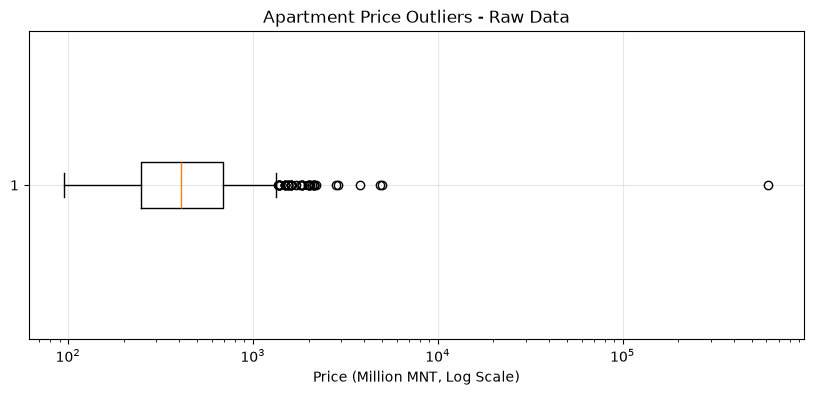

In [61]:
import matplotlib.pyplot as plt

# Select positive apartment prices.
prices = df_matched.loc[df_matched["price_mnt"] > 0, "price_mnt"]

plt.figure(figsize=(10, 4))

plt.boxplot(prices / 1_000_000, vert=False)

plt.xscale("log")
plt.title("Apartment Price Outliers - Raw Data")
plt.xlabel("Price (Million MNT, Log Scale)")
plt.grid(alpha=0.3)

plt.show()

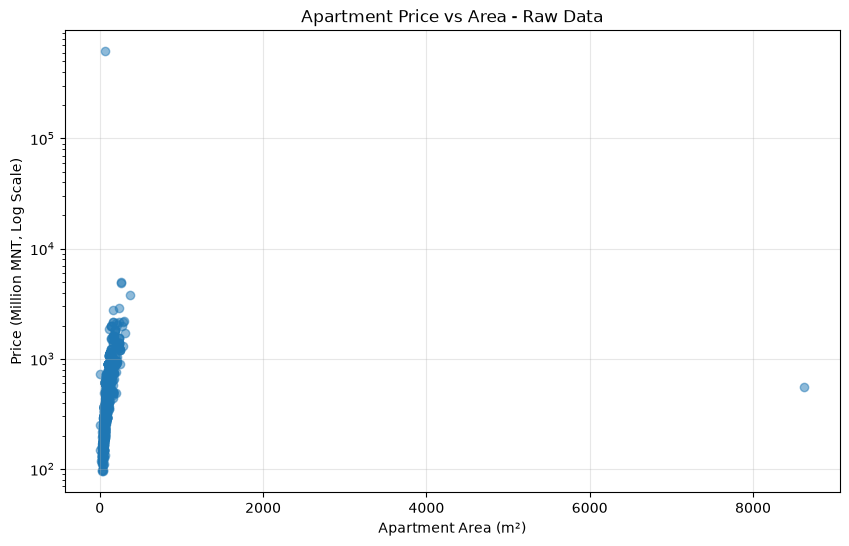

In [62]:
# Select valid positive values for plotting.
plot_df = df_matched[(df_matched["area_m2"] > 0) & (df_matched["price_mnt"] > 0)].copy()

plt.figure(figsize=(10, 6))

plt.scatter(plot_df["area_m2"], plot_df["price_mnt"] / 1_000_000, alpha=0.5)

plt.yscale("log")
plt.title("Apartment Price vs Area - Raw Data")
plt.xlabel("Apartment Area (m²)")
plt.ylabel("Price (Million MNT, Log Scale)")
plt.grid(alpha=0.3)

plt.show()

In [63]:
# Calculate the IQR for apartment prices.
Q1 = df_matched["price_mnt"].quantile(0.25)
Q3 = df_matched["price_mnt"].quantile(0.75)

IQR = Q3 - Q1

# Calculate the lower and upper limits.
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Find price outliers.
outlier_mask = (df_matched["price_mnt"] < lower_limit) | (
    df_matched["price_mnt"] > upper_limit
)

price_outliers = df_matched.loc[outlier_mask].copy()

# Keep prices within the limits.
within_limits = df_matched["price_mnt"].between(lower_limit, upper_limit)

df_no_outliers = df_matched.loc[within_limits].copy()

# Show the results.
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Original rows:", len(df_matched))
print("Price outliers:", len(price_outliers))
print("Missing prices:", df_matched["price_mnt"].isna().sum())
print("Remaining rows:", len(df_no_outliers))

Lower limit: -409075000.0
Upper limit: 1343125000.0
Original rows: 962
Price outliers: 43
Missing prices: 0
Remaining rows: 919


C:\Users\dashk\AppData\Local\Temp\ipykernel_74324\2623744531.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(prices / 1_000_000, vert=False)


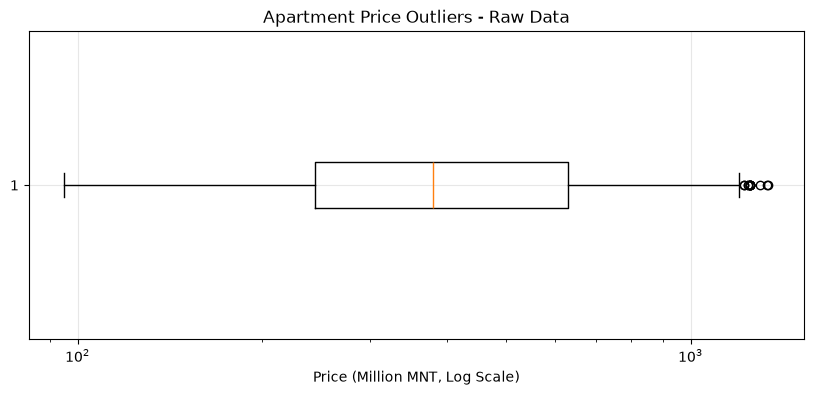

In [64]:
import matplotlib.pyplot as plt

# Select positive apartment prices.
prices = df_no_outliers.loc[df_no_outliers["price_mnt"] > 0, "price_mnt"]

plt.figure(figsize=(10, 4))

plt.boxplot(prices / 1_000_000, vert=False)

plt.xscale("log")
plt.title("Apartment Price Outliers - Raw Data")
plt.xlabel("Price (Million MNT, Log Scale)")
plt.grid(alpha=0.3)

plt.show()

In [65]:
# Calculate the IQR for apartment areas.
Q1_area = df_no_outliers["area_m2"].quantile(0.25)
Q3_area = df_no_outliers["area_m2"].quantile(0.75)

IQR_area = Q3_area - Q1_area

# Calculate the lower and upper limits.
lower_area = Q1_area - 1.5 * IQR_area
upper_area = Q3_area + 1.5 * IQR_area

# Find area outliers.
area_outlier_mask = (df_no_outliers["area_m2"] < lower_area) | (
    df_no_outliers["area_m2"] > upper_area
)

area_outliers = df_no_outliers.loc[area_outlier_mask].copy()

# Keep areas within the limits.
within_area_limits = df_no_outliers["area_m2"].between(lower_area, upper_area)

df_clean = df_no_outliers.loc[within_area_limits].copy()

# Show the results.
print("Lower area limit:", lower_area)
print("Upper area limit:", upper_area)
print("Original rows:", len(df_no_outliers))
print("Area outliers:", len(area_outliers))
print("Missing areas:", df_no_outliers["area_m2"].isna().sum())
print("Remaining rows:", len(df_clean))


Lower area limit: -23.61250000000001
Upper area limit: 185.3675
Original rows: 919
Area outliers: 30
Missing areas: 0
Remaining rows: 889


C:\Users\dashk\AppData\Local\Temp\ipykernel_74324\2088605695.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(prices / 1_000_000, vert=False)


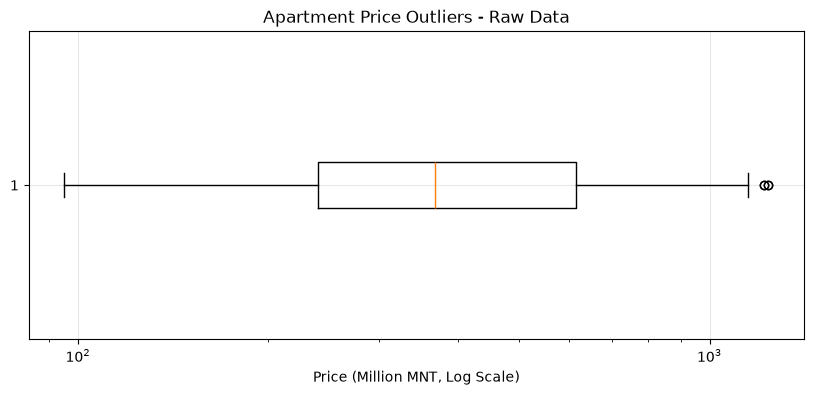

In [66]:
import matplotlib.pyplot as plt

# Select positive apartment prices.
prices = df_clean.loc[df_clean["price_mnt"] > 0, "price_mnt"]

plt.figure(figsize=(10, 4))

plt.boxplot(prices / 1_000_000, vert=False)

plt.xscale("log")
plt.title("Apartment Price Outliers - Raw Data")
plt.xlabel("Price (Million MNT, Log Scale)")
plt.grid(alpha=0.3)

plt.show()

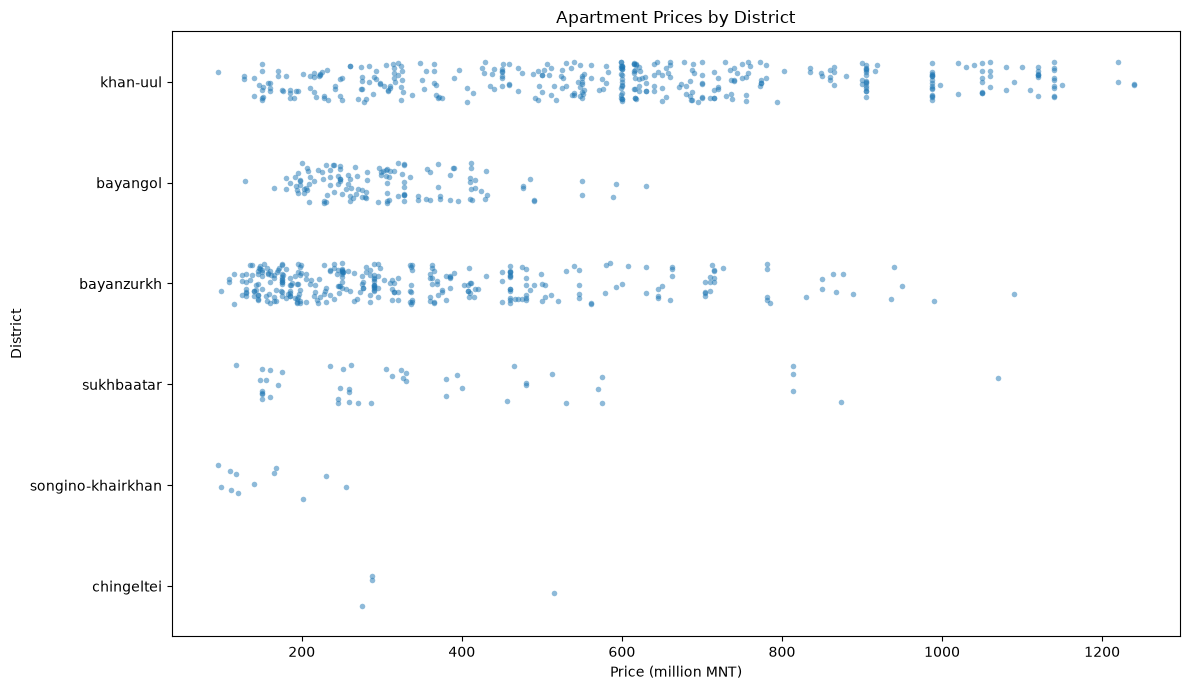

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a separate DataFrame for plotting.
plot_data = df_clean.copy()
plot_data["price_million_mnt"] = plot_data["price_mnt"] / 1_000_000

# Create the plot.
fig, ax = plt.subplots(figsize=(12, 7))

sns.stripplot(
    data=plot_data,
    x="price_million_mnt",
    y="city_region",
    jitter=0.2,
    alpha=0.5,
    size=4,
    ax=ax,
)

ax.set_title("Apartment Prices by District")
ax.set_xlabel("Price (million MNT)")
ax.set_ylabel("District")

plt.tight_layout()
plt.show()

In [68]:
df_clean.head()

,price_mnt,rooms,city_region,floor_material,balcony,building_year,garage,window_type,total_floors,door_type,area_m2,floor_number,payment_terms,window_count,construction_status,elevator,published_at,complex_name_clean
3,615000000,3,khan-uul,parquet,1 balcony,2022,not available,insulated glazing,25,security door,69.93,18,bank loan,4,completed,available,None,akademi khotkhon ph-1
4,450000000,3,khan-uul,parquet,1 balcony,2020,available,insulated glazing,16,security door,80.00,8,bank loan,3,completed,available,None,king tauer
6,988000000,4,khan-uul,parquet,1 balcony,2026,not available,insulated glazing,16,metal,152.00,16,cash payment,5,completed,available,None,king tauer
11,1140000000,4,khan-uul,parquet,1 balcony,2017,not available,insulated glazing,16,security door,120.00,11,bank loan,5,completed,available,None,river garden 1
15,281000000,2,bayangol,parquet,1 balcony,2026,not available,insulated glazing,16,security door,58.52,9,cash payment,4,completed,available,None,altai khotkhon


In [69]:
# output_path = project_dir / "data" / "df_clean.csv"
# df_clean.to_csv(output_path, index=False, encoding="utf-8-sig")
# print("File saved to:", output_path.resolve())

In [70]:
# Basic statistics.
df_clean.describe()

,price_mnt,rooms,building_year,total_floors,area_m2,floor_number,window_count
count,8.890000e+02,889.0,889.000000,889.000000,889.000000,889.000000,889.000000
mean,4.483745e+08,2.788526,2017.922385,13.570304,80.780624,8.085489,3.376828
std,2.663243e+08,0.862274,5.204127,4.310559,34.608376,5.032720,1.321497
min,9.500000e+07,1.0,1990.000000,1.000000,1.000000,1.000000,1.000000
25%,2.400000e+08,2.0,2014.000000,11.000000,54.000000,4.000000,2.000000
50%,3.673400e+08,3.0,2018.000000,14.000000,72.210000,8.000000,3.000000
75%,6.156500e+08,3.0,2022.000000,16.000000,105.300000,11.000000,4.000000
max,1.240000e+09,5.0,2026.000000,25.000000,185.000000,25.000000,8.000000


In [71]:
# Find apartments with an area smaller than 15 m².
small_area = df_clean["area_m2"] < 15

# Find apartments with incorrect floor information.
wrong_floor = df_clean["floor_number"] > df_clean["total_floors"]

# Count records before cleaning.
before = len(df_clean)

# Remove invalid records and update df_clean.
df_clean = df_clean[~(small_area | wrong_floor)].copy()

# Check the results.
print("Removed records:", before - len(df_clean))
print("Remaining records:", len(df_clean))

# Display the updated dataset.
display(df_clean)

Removed records: 13
Remaining records: 876


,price_mnt,rooms,city_region,floor_material,balcony,building_year,garage,window_type,total_floors,door_type,area_m2,floor_number,payment_terms,window_count,construction_status,elevator,published_at,complex_name_clean
3,615000000,3,khan-uul,parquet,1 balcony,2022,not available,insulated glazing,25,security door,69.93,18,bank loan,4,completed,available,None,akademi khotkhon ph-1
4,450000000,3,khan-uul,parquet,1 balcony,2020,available,insulated glazing,16,security door,80.00,8,bank loan,3,completed,available,None,king tauer
6,988000000,4,khan-uul,parquet,1 balcony,2026,not available,insulated glazing,16,metal,152.00,16,cash payment,5,completed,available,None,king tauer
11,1140000000,4,khan-uul,parquet,1 balcony,2017,not available,insulated glazing,16,security door,120.00,11,bank loan,5,completed,available,None,river garden 1
15,281000000,2,bayangol,parquet,1 balcony,2026,not available,insulated glazing,16,security door,58.52,9,cash payment,4,completed,available,None,altai khotkhon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3737,364950000,3,khan-uul,parquet,1 balcony,2016,available,insulated glazing,5,metal,97.00,3,bank loan,4,completed,not available,2026-10-26,dol khotkhon
3738,147700000,2,bayanzurkh,parquet,no balcony,2013,not available,insulated glazing,5,security door,38.00,1,bank loan,2,completed,not available,2026-10-26,erdem khotkhon
3749,138000000,2,bayanzurkh,parquet,1 balcony,2011,not available,insulated glazing,5,security door,39.00,1,cash payment,2,completed,not available,2026-10-26,baianzurkh khotkhon
3763,275000000,3,bayanzurkh,parquet,2 balconies,2021,not available,insulated glazing,12,security door,77.00,11,bank loan,3,completed,available,2026-10-25,"nart khoroolol 1, 2"


In [72]:
# Remove the published_at column.
df_clean = df_clean.drop(columns=["published_at"])
# Check the remaining columns.
print(df_clean.columns.tolist())

['price_mnt', 'rooms', 'city_region', 'floor_material', 'balcony', 'building_year', 'garage', 'window_type', 'total_floors', 'door_type', 'area_m2', 'floor_number', 'payment_terms', 'window_count', 'construction_status', 'elevator', 'complex_name_clean']


In [73]:
df_clean.head()

,price_mnt,rooms,city_region,floor_material,balcony,building_year,garage,window_type,total_floors,door_type,area_m2,floor_number,payment_terms,window_count,construction_status,elevator,complex_name_clean
3,615000000,3,khan-uul,parquet,1 balcony,2022,not available,insulated glazing,25,security door,69.93,18,bank loan,4,completed,available,akademi khotkhon ph-1
4,450000000,3,khan-uul,parquet,1 balcony,2020,available,insulated glazing,16,security door,80.00,8,bank loan,3,completed,available,king tauer
6,988000000,4,khan-uul,parquet,1 balcony,2026,not available,insulated glazing,16,metal,152.00,16,cash payment,5,completed,available,king tauer
11,1140000000,4,khan-uul,parquet,1 balcony,2017,not available,insulated glazing,16,security door,120.00,11,bank loan,5,completed,available,river garden 1
15,281000000,2,bayangol,parquet,1 balcony,2026,not available,insulated glazing,16,security door,58.52,9,cash payment,4,completed,available,altai khotkhon


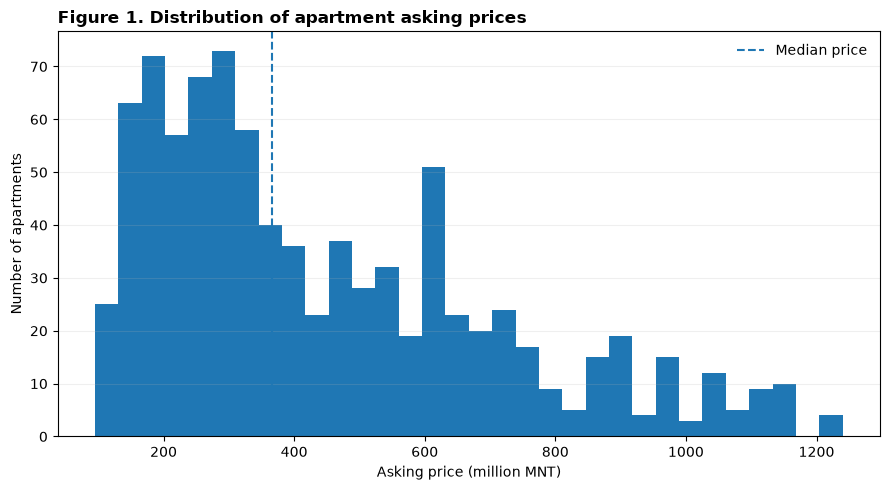

In [74]:
# Convert MNT into millions to make the axis easier to read.
prices = df_clean["price_mnt"] / 1_000_000

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(prices, bins=32)
ax.axvline(prices.median(), linestyle="--", label="Median price")
ax.set_title(
    "Figure 1. Distribution of apartment asking prices", loc="left", fontweight="bold"
)
ax.set_xlabel("Asking price (million MNT)")
ax.set_ylabel("Number of apartments")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("CA1_EDA_01_Price_Distribution.png", dpi=300, bbox_inches="tight")
plt.show()

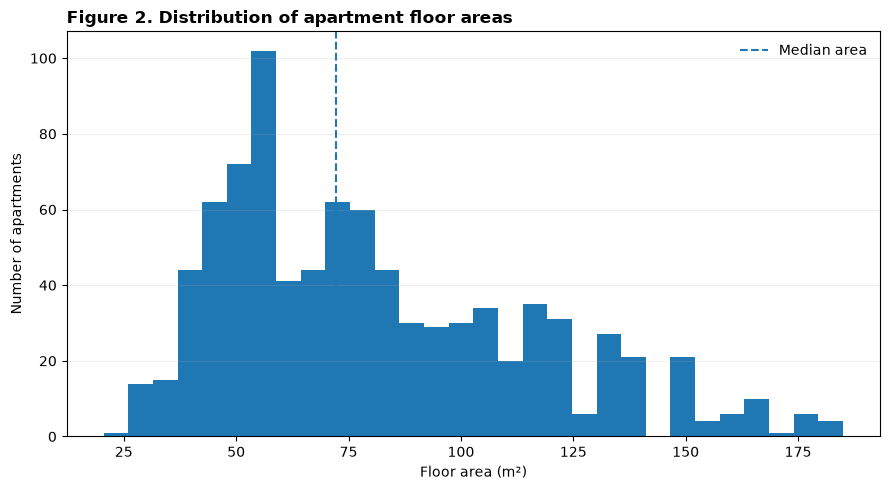

In [75]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df_clean["area_m2"], bins=30)
ax.axvline(df_clean["area_m2"].median(), linestyle="--", label="Median area")
ax.set_title(
    "Figure 2. Distribution of apartment floor areas", loc="left", fontweight="bold"
)
ax.set_xlabel("Floor area (m²)")
ax.set_ylabel("Number of apartments")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("CA1_EDA_02_Area_Distribution.png", dpi=300, bbox_inches="tight")
plt.show()

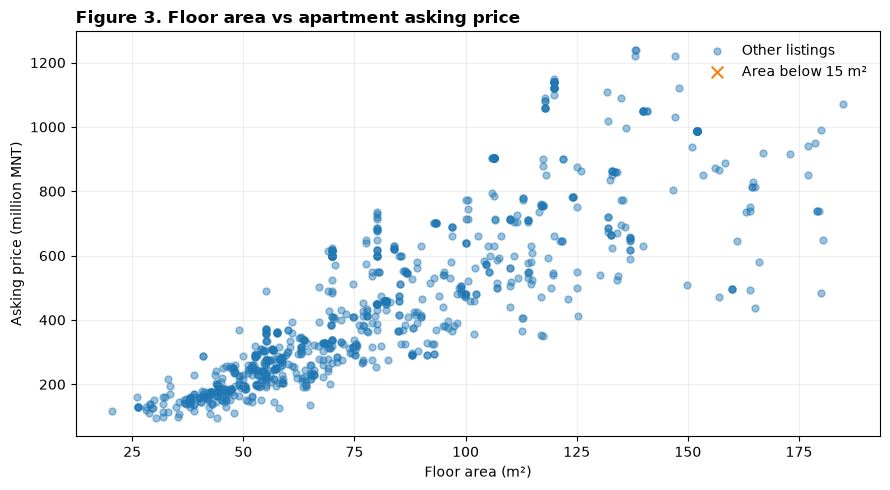

In [76]:
# Highlight extremely small areas so we do not forget to check them.
small = df_clean["area_m2"] < 15

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(
    df_clean.loc[~small, "area_m2"],
    df_clean.loc[~small, "price_mnt"] / 1_000_000,
    alpha=0.45,
    s=25,
    label="Other listings",
)
ax.scatter(
    df_clean.loc[small, "area_m2"],
    df_clean.loc[small, "price_mnt"] / 1_000_000,
    marker="x",
    s=70,
    label="Area below 15 m²",
)
ax.set_title(
    "Figure 3. Floor area vs apartment asking price", loc="left", fontweight="bold"
)
ax.set_xlabel("Floor area (m²)")
ax.set_ylabel("Asking price (million MNT)")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig("CA1_EDA_03_Area_vs_Price.png", dpi=300, bbox_inches="tight")
plt.show()

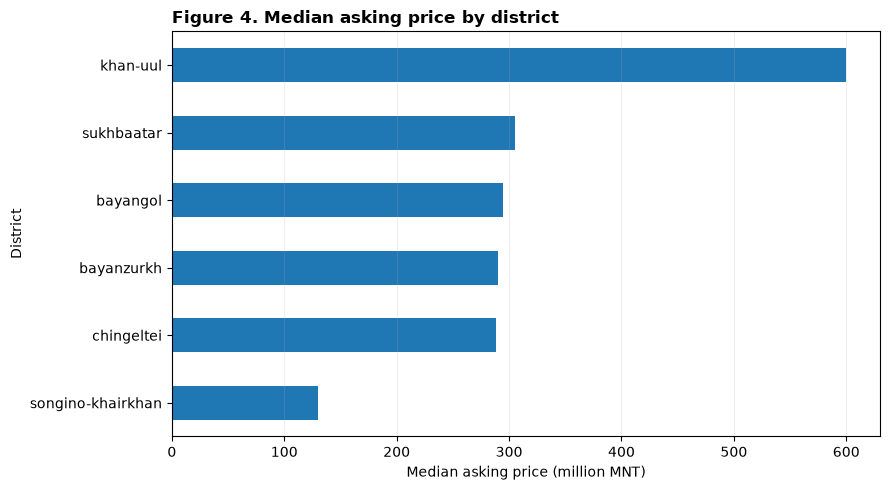

Listings by district:
city_region
khan-uul             368
bayanzurkh           314
bayangol             131
sukhbaatar            47
songino-khairkhan     12
chingeltei             4
Name: count, dtype: int64


In [77]:
district_price = (
    df_clean.groupby("city_region")["price_mnt"].median().sort_values() / 1_000_000
)

fig, ax = plt.subplots(figsize=(9, 5))
district_price.plot(kind="barh", ax=ax)
ax.set_title("Figure 4. Median asking price by district", loc="left", fontweight="bold")
ax.set_xlabel("Median asking price (million MNT)")
ax.set_ylabel("District")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig("CA1_EDA_04_Median_Price_by_District.png", dpi=300, bbox_inches="tight")
plt.show()

print("Listings by district:")
print(df_clean["city_region"].value_counts())

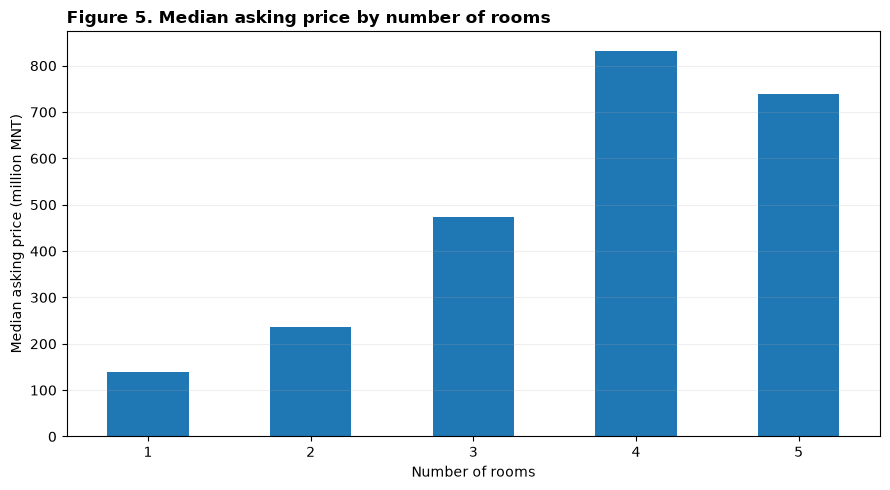

In [78]:
# Convert values such as "3 rooms" into the number 3.
# df_clean["room_number"] = df_clean["rooms"].str.extract(r"(\d+)").astype(int)
room_price = df_clean.groupby("rooms")["price_mnt"].median() / 1_000_000

fig, ax = plt.subplots(figsize=(9, 5))
room_price.plot(kind="bar", ax=ax)
ax.set_title(
    "Figure 5. Median asking price by number of rooms", loc="left", fontweight="bold"
)
ax.set_xlabel("Number of rooms")
ax.set_ylabel("Median asking price (million MNT)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig("CA1_EDA_05_Median_Price_by_Rooms.png", dpi=300, bbox_inches="tight")
plt.show()

In [79]:
df_clean.dtypes

price_mnt                int64
rooms                    Int64
city_region                str
floor_material             str
balcony                    str
building_year            int64
garage                     str
window_type                str
total_floors             int64
door_type                  str
area_m2                float64
floor_number             int64
payment_terms              str
window_count             int64
construction_status        str
elevator                   str
complex_name_clean         str
dtype: object

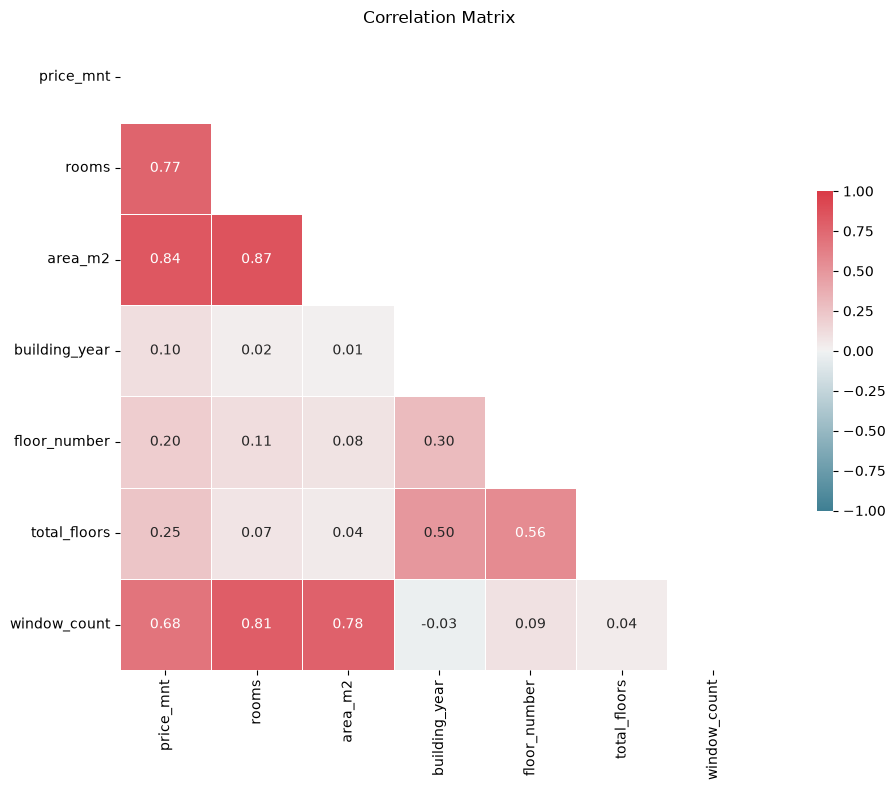

In [80]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Select the columns for correlation analysis.
selected_columns = [
    "price_mnt",
    "rooms",
    "area_m2",
    "building_year",
    "floor_number",
    "total_floors",
    "window_count",
]

# Calculate the correlation matrix.
corr = df_clean[selected_columns].corr()

# Hide the upper triangle.
mask = np.triu(np.ones_like(corr, dtype=bool))

# Create the figure and colour palette.
fig, ax = plt.subplots(figsize=(12, 8))
cmap = sns.diverging_palette(220, 10, as_cmap=True)

# Draw the heatmap.
sns.heatmap(
    corr,
    mask=mask,
    cmap=cmap,
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.5},
    ax=ax,
)

ax.set_title("Correlation Matrix")
plt.tight_layout()
plt.show()